# SEMMA: Predicting Student Final Grades

**Student:** Arti Ramesh Nalawade  
**Student ID:** 020757113

**My project question:** Can I estimate a student's final mathematics grade using their study habits, attendance and other background information, without using earlier exam grades?

**Simple answer:** I can make an estimate, but it will not be perfect. I will compare a simple baseline, Ridge Regression and Random Forest to see how useful the predictions are.

**What this notebook does:** It follows the five SEMMA stages: Sample, Explore, Modify, Model and Assess. I use a public Kaggle dataset, explain the steps in simple language and save the final model to show that it can predict a new record.

**How to run:** Upload this notebook to Google Colab and select **Runtime -> Run all**. No API keys are needed for the ML code. If Kaggle access fails, stop and fix the download. Do not substitute an unrelated dataset.

**Important:** The final scores below are generated only when you run the notebook. Grades are on a 0 to 20 scale. This is a learning project, not a tool for judging or penalizing students.

## Stage 1 - Sample

First, I download student data from Kaggle. Each row represents one student. `G3` is the final mathematics grade that I want to predict. `G1` and `G2` are earlier grades. I remove them because I want to see what the other information tells me on its own.

I keep 20% of the data aside as a final test set. From the remaining 80%, I create a training set and a validation set. **Training** is for learning, **validation** is for choosing a model, and **testing** is for the final fair check.

The random seed makes the split repeatable.

In [1]:
!pip -q install kagglehub mlxtend joblib


In [2]:
import os
import glob
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_SOURCE = 'Kaggle: uciml/student-alcohol-consumption'

import kagglehub

p = kagglehub.dataset_download('uciml/student-alcohol-consumption')

files = glob.glob(
    os.path.join(p, '**', 'student-mat.csv'),
    recursive=True
)

if not files:
    raise FileNotFoundError('student-mat.csv was not found')

csv_path = files[0]

# Detect the actual file separator.
df = pd.read_csv(csv_path, sep=None, engine='python')

# Check that the expected columns are present.
required_columns = {'G1', 'G2', 'G3'}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f'Expected G1, G2 and G3, but found: {df.columns.tolist()}'
    )

# Convert grades to numbers and validate them.
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

if df['G3'].isna().any():
    raise ValueError('Some final grades are missing or invalid.')

print('SOURCE:', DATA_SOURCE)
print('Dataset shape:', df.shape)
display(df.head())

# SEMMA Step 1: Sample - keep the final test set separate.
from sklearn.model_selection import train_test_split

sample = df.sample(frac=1, random_state=42)
y = sample['G3']
X = sample.drop(columns=['G3', 'G1', 'G2'])

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42
)

print('Full sample:', len(sample))
print('Training records:', len(X_train))
print('Validation records:', len(X_val))
print('Final test records:', len(X_test))
assert not (set(X_train.index) & set(X_val.index))
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))

Using Colab cache for faster access to the 'student-alcohol-consumption' dataset.
SOURCE: Kaggle: uciml/student-alcohol-consumption
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Full sample: 395
Training records: 237
Validation records: 79
Final test records: 79


## Stage 2 - Explore

I look at missing values, duplicate rows and the spread of final grades. A chart helps me see whether many students have similar grades. I also check which columns contain numbers and which contain words or categories.

This is about understanding the data, not proving that one factor *causes* a grade to change. The dataset covers a particular group of students, so my results may not apply to every school.

Missing values: 0
Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


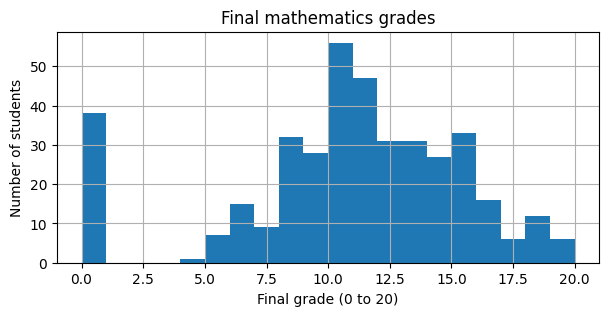

Feature types: {dtype('O'): 17, dtype('int64'): 13}


In [3]:
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
display(df.describe(include='all').T.head(12))
fig, ax = plt.subplots(figsize=(7, 3))
df['G3'].hist(bins=20, ax=ax)
ax.set_title('Final mathematics grades')
ax.set_xlabel('Final grade (0 to 20)')
ax.set_ylabel('Number of students')
plt.show()
print('Feature types:', X.dtypes.value_counts().to_dict())

## Stage 3 - Modify

Models need clean, consistent data. For numeric columns, I fill missing values with a typical value and scale the numbers. For text columns, I fill missing values and turn categories into indicator columns.

I put all these steps in a **pipeline**, which is like a recipe that applies the same preparation to training data and to new student records. The recipe learns its preparation rules only from the relevant training rows, so the final test set cannot leak information into the model.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib

numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
category_columns = X.columns.difference(numeric_columns).tolist()

prep = ColumnTransformer([
    ('numbers', Pipeline([
        ('missing', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), numeric_columns),
    ('categories', Pipeline([
        ('missing', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore'))
    ]), category_columns)
])

print('Numeric columns:', len(numeric_columns))
print('Categorical columns:', len(category_columns))

Numeric columns: 13
Categorical columns: 17


## Stage 4 - Model

I compare three ways to predict grades:

- **Baseline:** Predicts the average grade for everyone. This gives me a simple result to beat.
- **Ridge Regression:** Looks for a steady relationship between the input information and the grade.
- **Random Forest:** Uses many decision trees and combines their answers.

I compare these models using the **validation data**, not the final test data. I choose the model with the lowest validation MAE (average absolute error). After selecting it, I train it again using the full training portion and leave the test set untouched until the next stage.

In [5]:
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Ridge Regression': Pipeline([
        ('prepare', clone(prep)),
        ('model', Ridge(alpha=10))
    ]),
    'Random Forest': Pipeline([
        ('prepare', clone(prep)),
        ('model', RandomForestRegressor(
            n_estimators=120, min_samples_leaf=3,
            random_state=42, n_jobs=-1
        ))
    ])
}

validation_metrics = {}
for name, model in models.items():
    trained = clone(model)
    trained.fit(X_train, y_train)
    predictions = trained.predict(X_val)
    validation_metrics[name] = {
        'MAE': mean_absolute_error(y_val, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_val, predictions)),
        'R2': r2_score(y_val, predictions)
    }

validation_results = pd.DataFrame(validation_metrics).T.sort_values('MAE')
print('VALIDATION SCORES - used to choose the model')
display(validation_results.round(3))

selected_name = validation_results.index[0]
selected = clone(models[selected_name])
selected.fit(X_train_full, y_train_full)
print('Chosen model:', selected_name)
print('The final test set has not been used to choose this model.')

VALIDATION SCORES - used to choose the model


,MAE,RMSE,R2
Random Forest,3.182,4.406,0.284
Mean baseline,3.917,5.236,-0.011
Ridge Regression,4.152,5.218,-0.004


Chosen model: Random Forest
The final test set has not been used to choose this model.


## Stage 5 - Assess

Now I use the untouched **final test set** once to see how the chosen model handles students it has not learned from.

- **MAE:** On average, how many grade points is the model off by? Lower is better.
- **RMSE:** Another error measure that gives extra weight to large mistakes. Lower is better.
- **R2:** How much better the prediction fits than simply guessing the average? Higher is better. A small R2 means many factors affecting grades are still unexplained.

I also draw a chart comparing real grades and predicted grades. Because this model can be wrong, its predictions should not be used to punish or label students.

FINAL TEST EVALUATION - selected model only
Model: Random Forest
MAE: 2.374
RMSE: 3.184
R2: 0.276


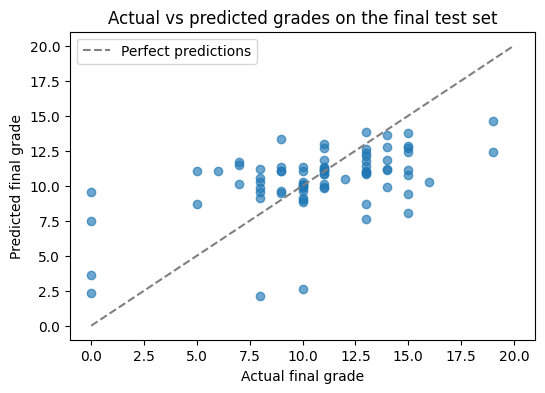

Simple conclusion: These inputs provide a rough estimate, not a guaranteed grade.
Do not make individual student decisions based only on this model.


In [6]:
final_predictions = selected.predict(X_test)
final_results = {
    'MAE': mean_absolute_error(y_test, final_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, final_predictions)),
    'R2': r2_score(y_test, final_predictions)
}
print('FINAL TEST EVALUATION - selected model only')
print('Model:', selected_name)
for metric, value in final_results.items():
    print(f'{metric}: {value:.3f}')

plt.figure(figsize=(6, 4))
plt.scatter(y_test, final_predictions, alpha=0.65)
plt.xlabel('Actual final grade')
plt.ylabel('Predicted final grade')
plt.title('Actual vs predicted grades on the final test set')
plt.plot([0, 20], [0, 20], '--', color='gray', label='Perfect predictions')
plt.legend()
plt.show()

print('Simple conclusion: These inputs provide a rough estimate, not a guaranteed grade.')
print('Do not make individual student decisions based only on this model.')

## Practical delivery - Save and try the model

SEMMA ends with Assess. For my assignment, I also show a small working prediction demo. I save the trained model and all preparation steps into one file, load it again and predict one student from the test data. This is an **inference demo**, not a hosted application.

For a real-world use case, I would need to monitor error rates, data changes and possible unfair impacts.

In [7]:
import os
os.makedirs('artifacts', exist_ok=True)

model_file = 'artifacts/student_grade_pipeline.joblib'
joblib.dump(selected, model_file)
loaded = joblib.load(model_file)

example_row = X_test.iloc[[0]]
example_prediction = float(loaded.predict(example_row)[0])
print('Chosen model:', selected_name)
print('Predicted grade:', round(example_prediction, 2))
print('Actual grade:', float(y_test.iloc[0]))
assert np.allclose(loaded.predict(example_row), selected.predict(example_row))

validation_results.to_csv('artifacts/validation_model_comparison.csv')
pd.DataFrame([{'selected_model': selected_name, **final_results}]).to_csv(
    'artifacts/final_test_metrics.csv', index=False
)
print('Saved model, validation scores and final test results in artifacts/.')

Chosen model: Random Forest
Predicted grade: 8.69
Actual grade: 5.0
Saved model, validation scores and final test results in artifacts/.


## AI critique and changes made

**Reviewer role requested:** A strict, experienced SEMMA and data science methodology reviewer. These notes summarize the issues reviewed during our assignment discussion. They should not be presented as a separately run Claude or GPT-5 session unless you actually perform that review.

**Issue 1 - Research question did not match the code.** The original question referred to earlier grades, but `G1` and `G2` were removed. **Change:** The question now clearly says that earlier grades are not used. I also explain that the results are estimates, not guaranteed grades.

**Issue 2 - Choosing a model on test results is not a fair final assessment.** The earlier notebook compared models on the test set and saved Ridge for the demo. **Change:** This revised notebook compares models using validation data, selects the lowest validation MAE, refits the chosen model and then performs a separate final test.

**Issue 3 - Reproducibility and delivery.** **Change:** The notebook keeps a repeatable random seed, clearly prints validation and test results, and saves the selected pipeline plus metrics.

**Manual verification still needed:** After running in Colab, check that the Kaggle data has 395 rows and 33 columns, that validation and final test results appear, and that the saved model produces an example prediction. Also ask your professor-approved GPT/Claude reviewer to critique any remaining sections and save its real feedback.

In [8]:
import shutil
shutil.make_archive('SEMMA_artifacts','zip','artifacts')
print('Download SEMMA_artifacts.zip in Colab Files sidebar')


Download SEMMA_artifacts.zip in Colab Files sidebar
